## 1. Đọc và kiểm tra dữ liệu nguồn

In [1]:
import pandas as pd 

In [2]:
df=pd.read_csv("../Data/raw/synthetic_customers_10cols.csv",dtype={"customer_id":"string"})
print( "rows,cols: ", df.shape)
df.head()

rows,cols:  (100000, 10)


,customer_id,name,first_purchase_date,last_purchase_date,total_spent,avg_order_value,loyalty_points,favorite_category,subscription,support_tickets
0,CUST-45131,Jessica Jenkins,2022-10-23,2024-10-27,3265.97,71.00,4822,Toys,False,1
1,CUST-74728,Miranda Turner,2022-03-18,2024-07-20,8016.76,190.88,1998,Electronics,False,8
2,CUST-57845,Kelly Smith,2020-09-04,2025-01-25,7828.50,186.39,1486,Books,False,6
3,CUST-88800,Kenneth Smith,2022-10-16,2024-05-10,4184.57,92.99,2697,Beauty,True,3
4,CUST-91943,Brian Miller,2020-06-21,2024-07-25,2559.50,134.71,3362,Home & Kitchen,False,8


### 1.1. Kiểm tra mã khách hàng lặp

In [3]:
so_id_trung=df["customer_id"].duplicated().sum()
so_id_khac_nhau=len(df)-so_id_trung
print("Số customer_id trùng nhau: ", so_id_trung)
print("số customer_id khác nhau ", so_id_khac_nhau)

Số customer_id trùng nhau:  39487
số customer_id khác nhau  60513


In [4]:
id_lap=df.loc[df["customer_id"].duplicated(keep=False)] # Những dòng trùng ID
if id_lap.empty:
    print("không có customer_id nào bị lặp")
else:
    example_id=id_lap["customer_id"].iloc[0] # lấy ra custom_id đầu tiền trong số những id trùng
    example_gr=df.loc[df["customer_id"]==example_id] # lấy ra những dòng cùn cus_id với bảng trên 
    print("Id đang kiểm tra: ",example_id)
    display(example_gr)

Id đang kiểm tra:  CUST-45131


,customer_id,name,first_purchase_date,last_purchase_date,total_spent,avg_order_value,loyalty_points,favorite_category,subscription,support_tickets
0,CUST-45131,Jessica Jenkins,2022-10-23,2024-10-27,3265.97,71.00,4822,Toys,False,1
98112,CUST-45131,Robert Williams,2020-07-03,2024-06-08,4475.76,372.98,2310,Toys,True,9


* Đếm số tên khác nhau

In [5]:
so_ten_moi_id=df.groupby("customer_id")["name"].nunique()
so_ten_moi_id.head(10)




customer_id
CUST-10001    2
CUST-10002    1
CUST-10005    1
CUST-10006    2
CUST-10007    1
CUST-10009    1
CUST-10012    1
CUST-10013    2
CUST-10014    1
CUST-10015    1
Name: name, dtype: int64

In [6]:

so_ten_moi_id = df.groupby("customer_id")["name"].nunique()

id_nhieu_ten = so_ten_moi_id[so_ten_moi_id > 1]

print("Số ID có nhiều tên khác nhau:", len(id_nhieu_ten))
print(id_nhieu_ten.head(10))

Số ID có nhiều tên khác nhau: 27490
customer_id
CUST-10001    2
CUST-10006    2
CUST-10013    2
CUST-10017    3
CUST-10018    2
CUST-10020    2
CUST-10021    2
CUST-10026    2
CUST-10030    2
CUST-10031    4
Name: name, dtype: int64


In [7]:
so_dong_moi_id=df.groupby("customer_id").size()
so_dong_moi_id.head(10)

customer_id
CUST-10001    2
CUST-10002    1
CUST-10005    1
CUST-10006    2
CUST-10007    1
CUST-10009    1
CUST-10012    1
CUST-10013    2
CUST-10014    1
CUST-10015    1
dtype: int64

In [8]:
Bang_so_sanh=pd.DataFrame({"so_dong":so_dong_moi_id, "so_ten_khac_nhau":so_ten_moi_id})
Bang_so_sanh.head(10)

,so_dong,so_ten_khac_nhau
customer_id,,
CUST-10001,2,2
CUST-10002,1,1
CUST-10005,1,1
CUST-10006,2,2
CUST-10007,1,1
CUST-10009,1,1
CUST-10012,1,1
CUST-10013,2,2
CUST-10014,1,1


In [9]:
bang_id_lap=Bang_so_sanh.loc[Bang_so_sanh["so_dong"]>1]
print(len(bang_id_lap))
display(bang_id_lap)

27490


,so_dong,so_ten_khac_nhau
customer_id,,
CUST-10001,2,2
CUST-10006,2,2
CUST-10013,2,2
CUST-10017,3,3
CUST-10018,2,2
...,...,...
CUST-99983,3,3
CUST-99984,5,5
CUST-99990,2,2


In [10]:
print("so dong id bi trung", (Bang_so_sanh["so_dong"]>1).sum())
print("so dong id khong bi trung",(Bang_so_sanh["so_dong"]==1).sum())


so dong id bi trung 27490
so dong id khong bi trung 33023


* Đếm xem có tên có bị lặp không

In [11]:
cung_so_luong=(bang_id_lap["so_dong"]==bang_id_lap["so_ten_khac_nhau"])
print("Số id có mỗi dòng mang 1 tên khách nhau", cung_so_luong.sum())
print("Số id có tên lặp:", (~cung_so_luong).sum())

Số id có mỗi dòng mang 1 tên khách nhau 27490
Số id có tên lặp: 0


### Vì sao dùng `record_id`?

Có 27.490 giá trị `customer_id` xuất hiện nhiều lần. Trong các nhóm mã lặp,
mỗi dòng mang một tên khác nhau. Vì vậy, quy trình giữ từng hồ sơ và cấp
`record_id` duy nhất để nối kết quả phân cụm về bảng sạch.

# EDA

### 1.2. Kiểm tra kiểu dữ liệu, giá trị thiếu và ngày mua

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          100000 non-null  string 
 1   name                 100000 non-null  str    
 2   first_purchase_date  100000 non-null  str    
 3   last_purchase_date   100000 non-null  str    
 4   total_spent          100000 non-null  float64
 5   avg_order_value      100000 non-null  float64
 6   loyalty_points       100000 non-null  int64  
 7   favorite_category    100000 non-null  str    
 8   subscription         100000 non-null  bool   
 9   support_tickets      100000 non-null  int64  
dtypes: bool(1), float64(2), int64(2), str(4), string(1)
memory usage: 11.8 MB


In [13]:
so_o_thieu=df.isna().sum()
so_o_thieu/len(df) *100

customer_id            0.0
name                   0.0
first_purchase_date    0.0
last_purchase_date     0.0
total_spent            0.0
avg_order_value        0.0
loyalty_points         0.0
favorite_category      0.0
subscription           0.0
support_tickets        0.0
dtype: float64

* Chuyển firt_date, last_date sang format datetime

In [14]:
first_time = pd.to_datetime(
    df["first_purchase_date"], format= "%Y-%m-%d", errors="coerce"
)
print(first_time.head())
print("kieu du lieu ", first_time.dtype )

0   2022-10-23
1   2022-03-18
2   2020-09-04
3   2022-10-16
4   2020-06-21
Name: first_purchase_date, dtype: datetime64[us]
kieu du lieu  datetime64[us]


In [15]:
last_time = pd.to_datetime(
    df["last_purchase_date"], format= "%Y-%m-%d", errors="coerce"
)
print(last_time.head())
print("kieu du lieu ", last_time.dtype )

0   2024-10-27
1   2024-07-20
2   2025-01-25
3   2024-05-10
4   2024-07-25
Name: last_purchase_date, dtype: datetime64[us]
kieu du lieu  datetime64[us]


In [16]:
loi_ngaydau=(df["first_purchase_date"].notna() & first_time.isna()) # nếu dòng đó ko thiếu và dòng đó trả về nat thì sẽ in ra true
loi_ngaycuoi=(df["last_purchase_date"].notna() & last_time.isna())
print("So ngay ko chuyen duoc trong first_time",loi_ngaydau.sum())
print("So ngay ko chuyen duoc trong last_time",loi_ngaycuoi.sum())

So ngay ko chuyen duoc trong first_time 0
So ngay ko chuyen duoc trong last_time 0


In [17]:
display(
    df.loc[
        loi_ngaydau | loi_ngaycuoi,
        ["customer_id", "first_purchase_date", "last_purchase_date"]
    ].head(10)
)

,customer_id,first_purchase_date,last_purchase_date


In [18]:
sai_thu_tu_ngay=first_time>last_time
print("so dong sai thu tu ngay",sai_thu_tu_ngay.sum())

so dong sai thu tu ngay 0


In [19]:
display(
    df.loc[
        sai_thu_tu_ngay,
        ["customer_id", "first_purchase_date", "last_purchase_date"]
    ].head(10)
)

,customer_id,first_purchase_date,last_purchase_date


In [20]:
cot_so=["total_spent",
        "avg_order_value",
        "loyalty_points",
        "support_tickets"
]
df[cot_so].head(10)

,total_spent,avg_order_value,loyalty_points,support_tickets
0,3265.97,71.00,4822,1
1,8016.76,190.88,1998,8
2,7828.50,186.39,1486,6
3,4184.57,92.99,2697,3
4,2559.50,134.71,3362,8
5,9769.36,199.37,3556,6
6,4788.91,342.06,3611,7
7,2018.04,46.93,4847,3
8,7501.76,220.64,4945,2
9,8674.01,192.76,524,0


In [21]:
thong_ke_so=df[cot_so].describe()
display(thong_ke_so)

,total_spent,avg_order_value,loyalty_points,support_tickets
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,5025.910427,454.808671,2504.409090,4.995880
std,2876.821510,949.783626,1445.723651,3.168884
min,50.150000,1.040000,0.000000,0.000000
25%,2533.945000,99.460000,1252.000000,2.000000
50%,5031.075000,197.670000,2506.000000,5.000000
75%,7524.262500,386.790000,3757.000000,8.000000
max,9999.680000,9998.070000,5000.000000,10.000000


## 2. Khám phá dữ liệu và đánh giá đặc trưng

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

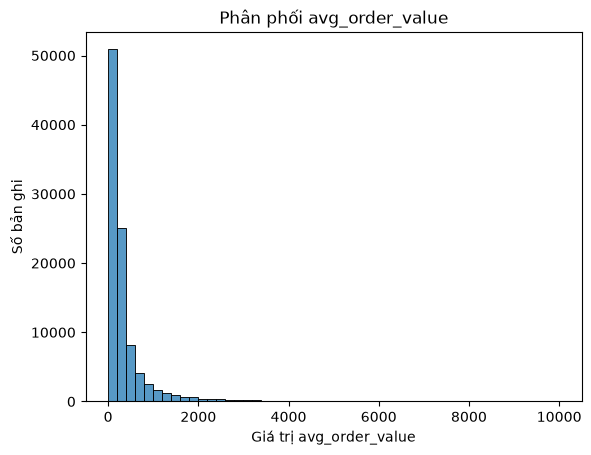

In [23]:
plt.Figure(figsize=(10,4))
sns.histplot(
    data=df,
    x="avg_order_value",
    bins=50
)
plt.title("Phân phối avg_order_value")
plt.xlabel("Giá trị avg_order_value")
plt.ylabel("Số bản ghi")
plt.show()

avg_order_value có phân phối lệch phải rõ rệt. Phần lớn bản ghi có giá trị thấp; một phần ít có giá trị cao, góp phần kéo mean lên trên median. Chưa đủ căn cứ để xem các giá trị cao là lỗi hoặc loại bỏ chúng.

In [24]:
cot_can_xem = [
    "customer_id",
    "name",
    "total_spent",
    "avg_order_value"
]

gia_tri_cao = df.nlargest(10, "avg_order_value")

display(gia_tri_cao[cot_can_xem])

,customer_id,name,total_spent,avg_order_value
70327,CUST-49176,Marissa Thomas,9998.07,9998.07
57167,CUST-94329,Kenneth Jordan,9995.05,9995.05
89775,CUST-41826,Sherry Calderon,9993.82,9993.82
18942,CUST-72898,Christopher Riley,9987.54,9987.54
78173,CUST-14840,Benjamin Johnson,9984.14,9984.14
26403,CUST-12711,Mark Dougherty,9978.77,9978.77
55149,CUST-20532,Andrea Gordon,9971.54,9971.54
72851,CUST-20742,Christopher Riley,9968.28,9968.28
56816,CUST-13274,Todd Williams,9967.81,9967.81
74768,CUST-31622,Jacqueline Lucas,9966.96,9966.96


In [25]:
nghi_van_gia_tri = df["avg_order_value"] > df["total_spent"]

print(
    "Số dòng có avg_order_value lớn hơn total_spent:",
    nghi_van_gia_tri.sum()
)

display(
    df.loc[nghi_van_gia_tri, cot_can_xem].head(10)
)

Số dòng có avg_order_value lớn hơn total_spent: 0


,customer_id,name,total_spent,avg_order_value


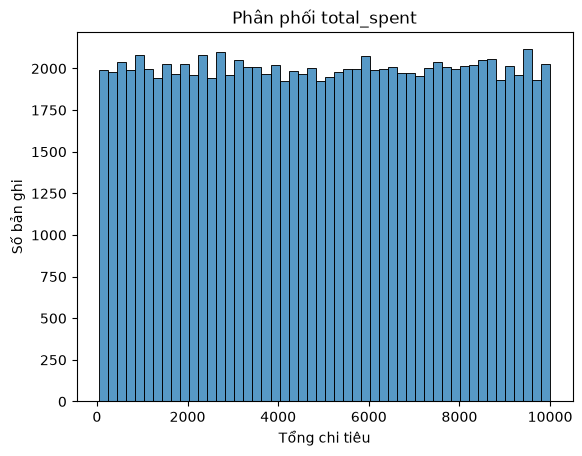

In [26]:
plt.Figure(figsize=(10,4))
sns.histplot(data=df, x="total_spent",bins=50)
plt.title("Phân phối total_spent")
plt.xlabel("Tổng chi tiêu")
plt.ylabel("Số bản ghi")
plt.show()

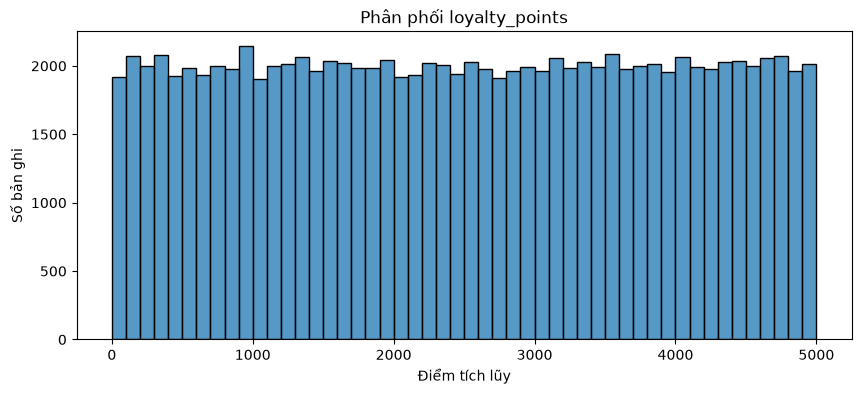

In [27]:
plt.figure(figsize=(10, 4))

sns.histplot(data=df, x="loyalty_points", bins=50)

plt.title("Phân phối loyalty_points")
plt.xlabel("Điểm tích lũy")
plt.ylabel("Số bản ghi")
plt.show()

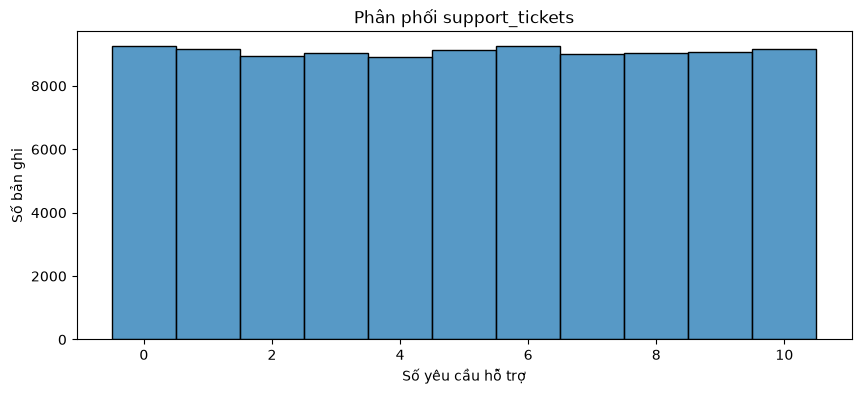

In [28]:
plt.figure(figsize=(10, 4))

sns.histplot(data=df, x="support_tickets", discrete=True)

plt.title("Phân phối support_tickets")
plt.xlabel("Số yêu cầu hỗ trợ")
plt.ylabel("Số bản ghi")
plt.show()

### 2.1. Kiểm tra giá trị ngoại lệ bằng IQR

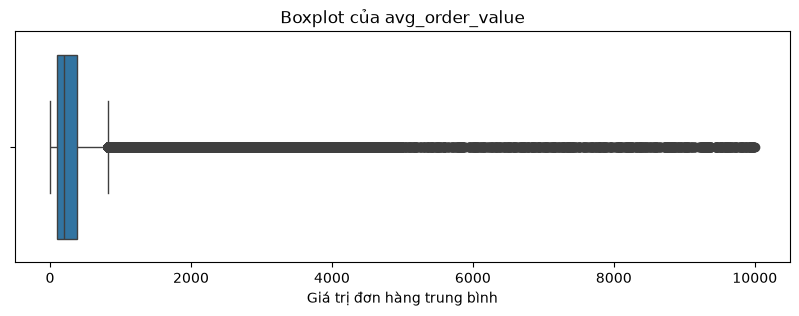

In [29]:
plt.figure(figsize=(10, 3))

sns.boxplot(data=df, x="avg_order_value")

plt.title("Boxplot của avg_order_value")
plt.xlabel("Giá trị đơn hàng trung bình")
plt.show()

In [30]:
q1 = df["avg_order_value"].quantile(0.25)
q3 = df["avg_order_value"].quantile(0.75)

iqr = q3 - q1

nguong_duoi = q1 - 1.5 * iqr
nguong_tren = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Ngưỡng dưới:", nguong_duoi)
print("Ngưỡng trên:", nguong_tren)

Q1: 99.46
Q3: 386.79
IQR: 287.33000000000004
Ngưỡng dưới: -331.5350000000001
Ngưỡng trên: 817.7850000000001


In [31]:
ngoai_nguong_iqr = (
    (df["avg_order_value"] < nguong_duoi)
    | (df["avg_order_value"] > nguong_tren)
)

so_dong_ngoai_nguong = ngoai_nguong_iqr.sum()
ty_le_ngoai_nguong = so_dong_ngoai_nguong / len(df) * 100

print("Số dòng ngoài ngưỡng IQR:", so_dong_ngoai_nguong)
print("Tỷ lệ (%):", ty_le_ngoai_nguong)

Số dòng ngoài ngưỡng IQR: 11408
Tỷ lệ (%): 11.408


### 2.2. Kiểm tra danh mục, trạng thái đăng ký và khoảng trắng

In [32]:
so_luong_danh_muc= df["favorite_category"].value_counts(dropna=False)
print(so_luong_danh_muc)
ty_le_danh_muc=df["favorite_category"].value_counts(normalize=True,dropna=False) *100
print(ty_le_danh_muc)

favorite_category
Home & Kitchen    14474
Clothing          14421
Books             14352
Sports            14272
Electronics       14206
Toys              14154
Beauty            14121
Name: count, dtype: int64
favorite_category
Home & Kitchen    14.474
Clothing          14.421
Books             14.352
Sports            14.272
Electronics       14.206
Toys              14.154
Beauty            14.121
Name: proportion, dtype: float64


In [33]:
so_luong_dang_ky= df["subscription"].value_counts(dropna=False)
print(so_luong_dang_ky)

ty_le_dang_ky= df["subscription"].value_counts(normalize=True,dropna=False)*100
print(ty_le_dang_ky)

subscription
False    50071
True     49929
Name: count, dtype: int64
subscription
False    50.071
True     49.929
Name: proportion, dtype: float64


* Kiểm tra khoảng trắng thừa, chuỗi rỗng

In [34]:
danh_muc_goc= df["favorite_category"]
danh_muc_bo_khoang_trang= danh_muc_goc.str.strip()

In [35]:
o_rong = danh_muc_bo_khoang_trang == ""

co_khoang_trang_thua = (
    danh_muc_goc != danh_muc_bo_khoang_trang
)

print("Số ô rỗng hoặc chỉ có khoảng trắng:", o_rong.sum())
print("Số ô có khoảng trắng đầu/cuối:", co_khoang_trang_thua.sum())

Số ô rỗng hoặc chỉ có khoảng trắng: 0
Số ô có khoảng trắng đầu/cuối: 0


In [36]:
can_xem = o_rong | co_khoang_trang_thua

print(
    danh_muc_goc.loc[can_xem]
    .head(10)
    .map(repr)
)

Series([], Name: favorite_category, dtype: str)


In [37]:
id_goc = df["customer_id"]
id_bo_khoang_trang = id_goc.str.strip()

id_rong = id_bo_khoang_trang == ""
id_thua_khoang_trang = id_goc != id_bo_khoang_trang

print("Số ID rỗng hoặc chỉ có khoảng trắng:", id_rong.sum())
print("Số ID có khoảng trắng đầu/cuối:", id_thua_khoang_trang.sum())

Số ID rỗng hoặc chỉ có khoảng trắng: 0
Số ID có khoảng trắng đầu/cuối: 0


In [38]:
ten_goc = df["name"]
ten_bo_khoang_trang = ten_goc.str.strip()

ten_rong = ten_bo_khoang_trang == ""
ten_thua_khoang_trang = ten_goc != ten_bo_khoang_trang

print("Số tên rỗng hoặc chỉ có khoảng trắng:", ten_rong.sum())
print("Số tên có khoảng trắng đầu/cuối:", ten_thua_khoang_trang.sum())

Số tên rỗng hoặc chỉ có khoảng trắng: 0
Số tên có khoảng trắng đầu/cuối: 0


In [39]:
print("Ví dụ ID cần kiểm tra:")
print(
    id_goc.loc[id_rong | id_thua_khoang_trang]
    .head(10)
    .map(repr)
)

print("Ví dụ tên cần kiểm tra:")
print(
    ten_goc.loc[ten_rong | ten_thua_khoang_trang]
    .head(10)
    .map(repr)
)

Ví dụ ID cần kiểm tra:
Series([], Name: customer_id, dtype: string)
Ví dụ tên cần kiểm tra:
Series([], Name: name, dtype: str)


In [40]:
print("Ngày mua đầu sớm nhất:", first_time.min())
print("Ngày mua đầu muộn nhất:", first_time.max())

print("Ngày mua cuối sớm nhất:", last_time.min())
print("Ngày mua cuối muộn nhất:", last_time.max())

Ngày mua đầu sớm nhất: 2020-05-04 00:00:00
Ngày mua đầu muộn nhất: 2024-05-03 00:00:00
Ngày mua cuối sớm nhất: 2024-05-04 00:00:00
Ngày mua cuối muộn nhất: 2025-05-04 00:00:00


### 2.3. Tính Recency từ ngày mua cuối

In [41]:
ngay_tham_chieu = pd.Timestamp("2025-05-05")

print(ngay_tham_chieu)

2025-05-05 00:00:00


In [42]:
khoang_cach_ngay = ngay_tham_chieu - last_time

print(khoang_cach_ngay.head())

0   190 days
1   289 days
2   100 days
3   360 days
4   284 days
Name: last_purchase_date, dtype: timedelta64[us]


In [43]:
recency = khoang_cach_ngay.dt.days

print(recency.head())

0    190
1    289
2    100
3    360
4    284
Name: last_purchase_date, dtype: int64


In [44]:
bang_recency = pd.DataFrame({
    "customer_id": df["customer_id"],
    "last_purchase_date": last_time,
    "recency_days": recency
})

display(bang_recency.head(10))

,customer_id,last_purchase_date,recency_days
0,CUST-45131,2024-10-27,190
1,CUST-74728,2024-07-20,289
2,CUST-57845,2025-01-25,100
3,CUST-88800,2024-05-10,360
4,CUST-91943,2024-07-25,284
5,CUST-47721,2025-03-15,51
6,CUST-79319,2025-04-02,33
7,CUST-32762,2025-01-02,123
8,CUST-48749,2024-06-09,330
9,CUST-81417,2024-07-27,282


In [45]:
print("Số giá trị thiếu:", recency.isna().sum())
print("Số giá trị âm:", (recency < 0).sum())
print("Recency nhỏ nhất:", recency.min())
print("Recency lớn nhất:", recency.max())

Số giá trị thiếu: 0
Số giá trị âm: 0
Recency nhỏ nhất: 1
Recency lớn nhất: 366


### 2.4. Đánh giá khả năng ước lượng Frequency

In [46]:
frequency_uoc_luong = (
    df["total_spent"] / df["avg_order_value"]
)

print(frequency_uoc_luong.head(10))

0    45.999577
1    41.998952
2    42.000644
3    45.000215
4    19.000074
5    49.001154
6    14.000205
7    43.001065
8    34.000000
9    44.999014
dtype: float64


In [47]:
bang_frequency = pd.DataFrame({
    "customer_id": df["customer_id"],
    "total_spent": df["total_spent"],
    "avg_order_value": df["avg_order_value"],
    "frequency_estimated": frequency_uoc_luong
})

display(bang_frequency.head(10))

,customer_id,total_spent,avg_order_value,frequency_estimated
0,CUST-45131,3265.97,71.00,45.999577
1,CUST-74728,8016.76,190.88,41.998952
2,CUST-57845,7828.50,186.39,42.000644
3,CUST-88800,4184.57,92.99,45.000215
4,CUST-91943,2559.50,134.71,19.000074
5,CUST-47721,9769.36,199.37,49.001154
6,CUST-79319,4788.91,342.06,14.000205
7,CUST-32762,2018.04,46.93,43.001065
8,CUST-48749,7501.76,220.64,34.000000
9,CUST-81417,8674.01,192.76,44.999014


In [48]:
display(frequency_uoc_luong.describe())


count    100000.000000
mean         25.480611
std          14.457054
min           1.000000
25%          12.999984
50%          25.003718
75%          38.000000
max          50.108808
dtype: float64

In [49]:
so_don_gia_dinh = frequency_uoc_luong.round()

khoang_cach_so_nguyen = (
    frequency_uoc_luong - so_don_gia_dinh
).abs()

print(khoang_cach_so_nguyen.head(10))

0    0.000423
1    0.001048
2    0.000644
3    0.000215
4    0.000074
5    0.001154
6    0.000205
7    0.001065
8    0.000000
9    0.000986
dtype: float64


In [50]:
display(
    khoang_cach_so_nguyen.describe(
        percentiles=[0.5, 0.95, 0.99]
    )
)

count    100000.000000
mean          0.001142
std           0.004493
min           0.000000
50%           0.000264
95%           0.003986
99%           0.015993
max           0.196429
dtype: float64

In [51]:
bang_kiem_tra_frequency = pd.DataFrame({
    "customer_id": df["customer_id"],
    "total_spent": df["total_spent"],
    "avg_order_value": df["avg_order_value"],
    "frequency_estimated": frequency_uoc_luong,
    "so_don_gia_dinh": so_don_gia_dinh,
    "khoang_cach": khoang_cach_so_nguyen
})

display(
    bang_kiem_tra_frequency.nlargest(10, "khoang_cach")
)

,customer_id,total_spent,avg_order_value,frequency_estimated,so_don_gia_dinh,khoang_cach
65056,CUST-87000,53.54,1.12,47.803571,48.0,0.196429
79176,CUST-46815,53.80,1.08,49.814815,50.0,0.185185
32350,CUST-58555,70.32,1.46,48.164384,48.0,0.164384
47383,CUST-54132,56.35,1.17,48.162393,48.0,0.162393
82579,CUST-45379,60.09,1.23,48.853659,49.0,0.146341
49457,CUST-37936,73.29,1.47,49.857143,50.0,0.142857
48926,CUST-15218,50.26,1.23,40.861789,41.0,0.138211
6804,CUST-35077,63.44,1.48,42.864865,43.0,0.135135
57198,CUST-22299,71.94,1.64,43.865854,44.0,0.134146
94276,CUST-59825,60.60,1.24,48.870968,49.0,0.129032


In [52]:
avg_tinh_lai = df["total_spent"] / so_don_gia_dinh

chenh_lech_avg = (
    df["avg_order_value"] - avg_tinh_lai
).abs()

print(chenh_lech_avg.head(10))

0    6.521739e-04
1    4.761905e-03
2    2.857143e-03
3    4.444444e-04
4    5.263158e-04
5    4.693878e-03
6    5.000000e-03
7    1.162791e-03
8    2.842171e-14
9    4.222222e-03
dtype: float64


In [53]:
nguong_lam_tron = 0.005
dung_sai_may_tinh = 1e-9

phu_hop_lam_tron = (
    chenh_lech_avg
    <= nguong_lam_tron + dung_sai_may_tinh
)

print("Số dòng phù hợp giả thuyết:",
      phu_hop_lam_tron.sum())

print("Số dòng cần xem thêm:",
      (~phu_hop_lam_tron).sum())

print("Chênh lệch lớn nhất:",
      chenh_lech_avg.max())

Số dòng phù hợp giả thuyết: 100000
Số dòng cần xem thêm: 0
Chênh lệch lớn nhất: 0.005000000000109139


In [54]:
bang_lam_tron = pd.DataFrame({
    "customer_id": df["customer_id"],
    "total_spent": df["total_spent"],
    "so_don_gia_dinh": so_don_gia_dinh,
    "avg_dang_luu": df["avg_order_value"],
    "avg_tinh_lai": avg_tinh_lai,
    "chenh_lech_avg": chenh_lech_avg
})

display(
    bang_lam_tron.loc[~phu_hop_lam_tron].head(10)
)

,customer_id,total_spent,so_don_gia_dinh,avg_dang_luu,avg_tinh_lai,chenh_lech_avg


In [55]:
mot_don_gia_dinh = so_don_gia_dinh == 1

print("Số bản ghi có số đơn giả định bằng 1:",
      mot_don_gia_dinh.sum())

Số bản ghi có số đơn giả định bằng 1: 2013


In [56]:
ngay_khac_nhau = first_time != last_time

nghi_van_mot_don = mot_don_gia_dinh & ngay_khac_nhau

print("Số bản ghi một đơn giả định nhưng hai ngày khác nhau:",
      nghi_van_mot_don.sum())

Số bản ghi một đơn giả định nhưng hai ngày khác nhau: 2013


In [57]:
bang_doi_chieu_ngay = pd.DataFrame({
    "customer_id": df["customer_id"],
    "first_purchase_date": first_time,
    "last_purchase_date": last_time,
    "total_spent": df["total_spent"],
    "avg_order_value": df["avg_order_value"],
    "so_don_gia_dinh": so_don_gia_dinh
})

display(
    bang_doi_chieu_ngay.loc[nghi_van_mot_don].head(10)
)

,customer_id,first_purchase_date,last_purchase_date,total_spent,avg_order_value,so_don_gia_dinh
111,CUST-29658,2024-02-21,2024-05-25,5509.42,5509.42,1.0
192,CUST-13808,2024-01-26,2024-08-22,1480.69,1480.69,1.0
232,CUST-47322,2022-01-13,2024-08-22,3965.94,3965.94,1.0
243,CUST-93957,2024-02-21,2024-06-23,793.08,793.08,1.0
336,CUST-16192,2022-03-21,2024-08-10,4068.92,4068.92,1.0
353,CUST-63974,2023-07-10,2024-09-23,3250.44,3250.44,1.0
467,CUST-46063,2021-09-14,2024-07-28,87.98,87.98,1.0
479,CUST-31527,2022-07-09,2025-04-14,2213.89,2213.89,1.0
504,CUST-65627,2023-03-19,2025-04-06,6164.55,6164.55,1.0
507,CUST-91011,2022-08-02,2024-06-24,1187.17,1187.17,1.0


### Quyết định về Frequency

Tỷ số `total_spent / avg_order_value` được thử như một cách ước lượng
số đơn. Có 2.013 hồ sơ được ước lượng là một đơn nhưng ngày mua đầu
và ngày mua cuối khác nhau. Quy trình dùng `recency_days` và
`total_spent` trong bảng đặc trưng. Frequency theo tháng cần ngày
của từng đơn hàng.

### 2.5. Phân tích tương quan và thang đo của các đặc trưng số

In [58]:
cot_so = [
    "total_spent",
    "avg_order_value",
    "loyalty_points",
    "support_tickets"
]

ma_tran_tuong_quan = df[cot_so].corr(method="pearson")

display(ma_tran_tuong_quan)

,total_spent,avg_order_value,loyalty_points,support_tickets
total_spent,1.000000,0.274839,-0.005492,0.004120
avg_order_value,0.274839,1.000000,0.004282,0.000097
loyalty_points,-0.005492,0.004282,1.000000,-0.002839
support_tickets,0.004120,0.000097,-0.002839,1.000000


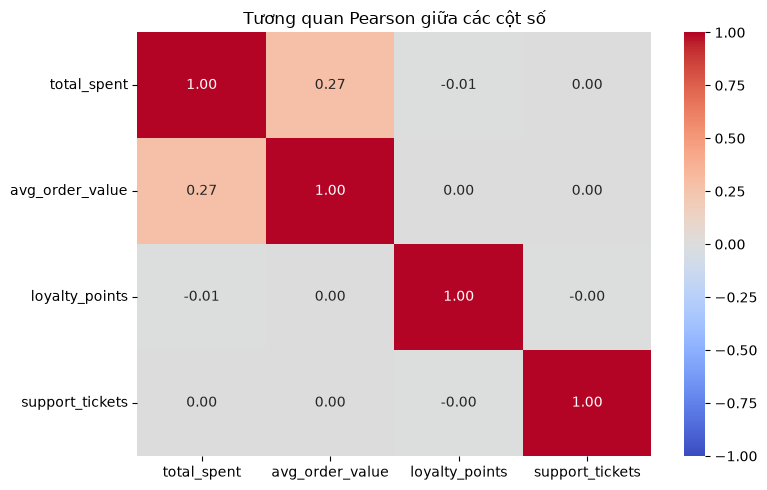

In [59]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    ma_tran_tuong_quan,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Tương quan Pearson giữa các cột số")
plt.tight_layout()
plt.show()

In [60]:
display(ma_tran_tuong_quan.round(4))

,total_spent,avg_order_value,loyalty_points,support_tickets
total_spent,1.0000,0.2748,-0.0055,0.0041
avg_order_value,0.2748,1.0000,0.0043,0.0001
loyalty_points,-0.0055,0.0043,1.0000,-0.0028
support_tickets,0.0041,0.0001,-0.0028,1.0000


In [61]:
cot_dac_trung = [
    "total_spent",
    "avg_order_value",
    "loyalty_points",
    "support_tickets",
    "subscription",
    "favorite_category"
]

dac_trung_thu = df[cot_dac_trung].copy()

In [62]:
dac_trung_thu["recency_days"] = recency

display(dac_trung_thu.head())

,total_spent,avg_order_value,loyalty_points,support_tickets,subscription,favorite_category,recency_days
0,3265.97,71.00,4822,1,False,Toys,190
1,8016.76,190.88,1998,8,False,Electronics,289
2,7828.50,186.39,1486,6,False,Books,100
3,4184.57,92.99,2697,3,True,Beauty,360
4,2559.50,134.71,3362,8,False,Home & Kitchen,284


In [63]:
print("Kích thước:", dac_trung_thu.shape)

print("Giữ nguyên thứ tự index:",
      dac_trung_thu.index.equals(df.index))

print("Số ô thiếu theo cột:")
print(dac_trung_thu.isna().sum())

print("Có Frequency ước lượng:",
      "frequency_estimated" in dac_trung_thu.columns)

Kích thước: (100000, 7)
Giữ nguyên thứ tự index: True
Số ô thiếu theo cột:
total_spent          0
avg_order_value      0
loyalty_points       0
support_tickets      0
subscription         0
favorite_category    0
recency_days         0
dtype: int64
Có Frequency ước lượng: False


In [64]:
cot_so_phan_tich = [
    "total_spent",
    "avg_order_value",
    "loyalty_points",
    "support_tickets",
    "recency_days"
]

do_lech = dac_trung_thu[cot_so_phan_tich].skew()

print(do_lech)

total_spent       -0.000373
avg_order_value    5.721402
loyalty_points    -0.003148
support_tickets   -0.001582
recency_days       0.006420
dtype: float64


In [65]:
print(do_lech.round(4))

total_spent       -0.0004
avg_order_value    5.7214
loyalty_points    -0.0031
support_tickets   -0.0016
recency_days       0.0064
dtype: float64


In [66]:
du_lieu_so = dac_trung_thu[cot_so_phan_tich]

bang_phan_tan = pd.DataFrame({
    "phuong_sai": du_lieu_so.var(ddof=1),
    "do_lech_chuan": du_lieu_so.std(ddof=1)
})

display(bang_phan_tan.round(4))

,phuong_sai,do_lech_chuan
total_spent,8.276102e+06,2876.8215
avg_order_value,9.020889e+05,949.7836
loyalty_points,2.090117e+06,1445.7237
support_tickets,1.004180e+01,3.1689
recency_days,1.112364e+04,105.4687


Phương sai và độ lệch chuẩn mẫu được tính cho năm đặc trưng số. Sự khác biệt về thang đo có thể khiến các cột có giá trị số lớn chi phối khoảng cách Euclid, nên cần chuẩn hóa trước khi phân cụm.

In [67]:
ma_tran_hiep_phuong_sai = du_lieu_so.cov(ddof=1)

display(ma_tran_hiep_phuong_sai.round(4))

,total_spent,avg_order_value,loyalty_points,support_tickets,recency_days
total_spent,8.276102e+06,750959.5255,-2.284271e+04,37.5636,1135.7379
avg_order_value,7.509595e+05,902088.9353,5.879435e+03,0.2922,436.6777
loyalty_points,-2.284271e+04,5879.4354,2.090117e+06,-13.0076,-150.9282
support_tickets,3.756360e+01,0.2922,-1.300760e+01,10.0418,-0.0872
recency_days,1.135738e+03,436.6777,-1.509282e+02,-0.0872,11123.6375


## 3. Thiết kế dữ liệu mô phỏng 5 nhóm

In [68]:
thiet_ke_nhom = pd.DataFrame({
    "nhom": [
        "Trung thành, chi tiêu cao",
        "Mua ít, đơn giá trị cao",
        "Khách mới",
        "Lâu chưa quay lại",
        "Mua thường xuyên, đơn nhỏ"
    ],
    "recency_dien_hinh": [15, 85, 10, 280, 30],
    "so_don_dien_hinh": [34, 5, 2, 14, 32],
    "gia_tri_don_dien_hinh": [180, 650, 75, 130, 55]
})

thiet_ke_nhom["tong_chi_tieu_minh_hoa"] = (
    thiet_ke_nhom["so_don_dien_hinh"]
    * thiet_ke_nhom["gia_tri_don_dien_hinh"]
)

display(thiet_ke_nhom)

,nhom,recency_dien_hinh,so_don_dien_hinh,gia_tri_don_dien_hinh,tong_chi_tieu_minh_hoa
0,"Trung thành, chi tiêu cao",15,34,180,6120
1,"Mua ít, đơn giá trị cao",85,5,650,3250
2,Khách mới,10,2,75,150
3,Lâu chưa quay lại,280,14,130,1820
4,"Mua thường xuyên, đơn nhỏ",30,32,55,1760


In [69]:
thiet_ke_sinh = thiet_ke_nhom.copy()

thiet_ke_sinh["std_recency"] = [5, 18, 4, 25, 8]
thiet_ke_sinh["std_so_don"] = [5, 2, 0.7, 4, 5]
thiet_ke_sinh["sigma_log_gia_tri_don"] = 0.25

display(thiet_ke_sinh)

,nhom,recency_dien_hinh,so_don_dien_hinh,gia_tri_don_dien_hinh,tong_chi_tieu_minh_hoa,std_recency,std_so_don,sigma_log_gia_tri_don
0,"Trung thành, chi tiêu cao",15,34,180,6120,5,5.0,0.25
1,"Mua ít, đơn giá trị cao",85,5,650,3250,18,2.0,0.25
2,Khách mới,10,2,75,150,4,0.7,0.25
3,Lâu chưa quay lại,280,14,130,1820,25,4.0,0.25
4,"Mua thường xuyên, đơn nhỏ",30,32,55,1760,8,5.0,0.25


In [70]:
import numpy as np

nhom_mau = thiet_ke_sinh.iloc[0]
so_ho_so = 10
rng = np.random.default_rng(42)

print(nhom_mau["nhom"])

Trung thành, chi tiêu cao


In [71]:
recency_tho = rng.normal(
    loc=nhom_mau["recency_dien_hinh"],
    scale=nhom_mau["std_recency"],
    size=so_ho_so
)

so_don_tho = rng.normal(
    loc=nhom_mau["so_don_dien_hinh"],
    scale=nhom_mau["std_so_don"],
    size=so_ho_so
)

recency_mau = np.clip(np.rint(recency_tho), 1, 366).astype(int)
so_don_mau = np.maximum(np.rint(so_don_tho), 1).astype(int)

print("Recency:", recency_mau)
print("Số đơn:", so_don_mau)

Recency: [17 10 19 20  5  8 16 13 15 11]
Số đơn: [38 38 34 40 36 30 36 29 38 34]


In [72]:
gia_tri_don_mau = rng.lognormal(
    mean=np.log(nhom_mau["gia_tri_don_dien_hinh"]),
    sigma=nhom_mau["sigma_log_gia_tri_don"],
    size=so_ho_so
).round(2)

tong_chi_tieu_mau = (so_don_mau * gia_tri_don_mau).round(2)

mau_trung_thanh = pd.DataFrame({
    "recency_days": recency_mau,
    "so_don": so_don_mau,
    "avg_order_value": gia_tri_don_mau,
    "total_spent": tong_chi_tieu_mau
})

display(mau_trung_thanh)
print("Kích thước bảng:", mau_trung_thanh.shape)

,recency_days,so_don,avg_order_value,total_spent
0,17,38,171.87,6531.06
1,10,38,151.82,5769.16
2,19,34,244.35,8307.90
3,20,40,173.18,6927.20
4,5,36,161.72,5821.92
5,8,30,164.83,4944.90
6,16,36,205.62,7402.32
7,13,29,197.22,5719.38
8,15,38,199.57,7583.66
9,11,34,200.47,6815.98


Kích thước bảng: (10, 4)


In [73]:
mau_co_ngay = mau_trung_thanh.copy()
ngay_tham_chieu_sinh = pd.Timestamp("2025-05-05")

khoang_recency = pd.to_timedelta(
    mau_co_ngay["recency_days"],
    unit="D"
)

mau_co_ngay["last_purchase_date"] = (
    ngay_tham_chieu_sinh - khoang_recency
)

display(mau_co_ngay[["recency_days", "last_purchase_date"]])

,recency_days,last_purchase_date
0,17,2025-04-18
1,10,2025-04-25
2,19,2025-04-16
3,20,2025-04-15
4,5,2025-04-30
5,8,2025-04-27
6,16,2025-04-19
7,13,2025-04-22
8,15,2025-04-20
9,11,2025-04-24


In [74]:
recency_tinh_lai = (
    ngay_tham_chieu_sinh - mau_co_ngay["last_purchase_date"]
).dt.days

khop_recency = recency_tinh_lai == mau_co_ngay["recency_days"]

print("Số hồ sơ khớp Recency:", khop_recency.sum())
print("Tổng số hồ sơ:", len(mau_co_ngay))

Số hồ sơ khớp Recency: 10
Tổng số hồ sơ: 10


In [75]:
khoang_mua_mau = rng.integers(
    low=365,
    high=731,
    size=len(mau_co_ngay)
)

mot_don = mau_co_ngay["so_don"] == 1
khoang_mua_mau = np.where(mot_don, 0, khoang_mua_mau)

mau_co_ngay["first_purchase_date"] = (
    mau_co_ngay["last_purchase_date"]
    - pd.to_timedelta(khoang_mua_mau, unit="D")
)

display(mau_co_ngay[[
    "so_don",
    "first_purchase_date",
    "last_purchase_date"
]])

,so_don,first_purchase_date,last_purchase_date
0,38,2023-05-17,2025-04-18
1,38,2023-07-28,2025-04-25
2,34,2023-12-04,2025-04-16
3,40,2023-04-27,2025-04-15
4,36,2023-12-02,2025-04-30
5,30,2023-12-30,2025-04-27
6,36,2023-05-24,2025-04-19
7,29,2023-12-09,2025-04-22
8,38,2024-03-24,2025-04-20
9,34,2023-11-05,2025-04-24


In [76]:
ngay_dau = mau_co_ngay["first_purchase_date"]
ngay_cuoi = mau_co_ngay["last_purchase_date"]

print("Số hồ sơ có ngày mua đầu sau ngày mua cuối:",
      (ngay_dau > ngay_cuoi).sum())

print("Số hồ sơ có một đơn:",
      mot_don.sum())

print("Số hồ sơ một đơn nhưng hai ngày khác nhau:",
      (mot_don & (ngay_dau != ngay_cuoi)).sum())

Số hồ sơ có ngày mua đầu sau ngày mua cuối: 0
Số hồ sơ có một đơn: 0
Số hồ sơ một đơn nhưng hai ngày khác nhau: 0


In [77]:
so_ho_so_mau = len(mau_co_ngay)
so_thu_tu = range(1, so_ho_so_mau + 1)

mau_co_ngay["customer_id"] = [f"SIM-{i:05d}" for i in so_thu_tu]
mau_co_ngay["name"] = [f"Khách mô phỏng {i:05d}" for i in so_thu_tu]

display(mau_co_ngay[["customer_id", "name"]])

,customer_id,name
0,SIM-00001,Khách mô phỏng 00001
1,SIM-00002,Khách mô phỏng 00002
2,SIM-00003,Khách mô phỏng 00003
3,SIM-00004,Khách mô phỏng 00004
4,SIM-00005,Khách mô phỏng 00005
5,SIM-00006,Khách mô phỏng 00006
6,SIM-00007,Khách mô phỏng 00007
7,SIM-00008,Khách mô phỏng 00008
8,SIM-00009,Khách mô phỏng 00009
9,SIM-00010,Khách mô phỏng 00010


In [78]:
print("Số hồ sơ:", len(mau_co_ngay))
print("Số mã khác nhau:", mau_co_ngay["customer_id"].nunique())
print("ID duy nhất:", mau_co_ngay["customer_id"].is_unique)

Số hồ sơ: 10
Số mã khác nhau: 10
ID duy nhất: True


In [79]:
so_ho_so_mau = len(mau_co_ngay)

mau_co_ngay["loyalty_points"] = rng.integers(
    low=0,
    high=5001,
    size=so_ho_so_mau
)

mau_co_ngay["support_tickets"] = rng.integers(
    low=0,
    high=11,
    size=so_ho_so_mau
)

display(mau_co_ngay[[
    "customer_id",
    "loyalty_points",
    "support_tickets"
]])

,customer_id,loyalty_points,support_tickets
0,SIM-00001,3979,10
1,SIM-00002,947,4
2,SIM-00003,2315,1
3,SIM-00004,649,9
4,SIM-00005,3433,6
5,SIM-00006,2379,7
6,SIM-00007,1651,1
7,SIM-00008,1134,3
8,SIM-00009,2823,8
9,SIM-00010,3349,9


In [80]:
diem_hop_le = mau_co_ngay["loyalty_points"].between(0, 5000)
yeu_cau_hop_le = mau_co_ngay["support_tickets"].between(0, 10)

print("Tất cả điểm nằm trong khoảng:", diem_hop_le.all())
print("Tất cả số yêu cầu nằm trong khoảng:", yeu_cau_hop_le.all())

Tất cả điểm nằm trong khoảng: True
Tất cả số yêu cầu nằm trong khoảng: True


In [81]:
so_ho_so_mau = len(mau_co_ngay)
danh_muc_nguon = df["favorite_category"].dropna().unique()

mau_co_ngay["favorite_category"] = rng.choice(
    danh_muc_nguon,
    size=so_ho_so_mau,
    replace=True
)

mau_co_ngay["subscription"] = rng.choice(
    [False, True],
    size=so_ho_so_mau,
    replace=True
)

display(mau_co_ngay[[
    "customer_id",
    "favorite_category",
    "subscription"
]])

,customer_id,favorite_category,subscription
0,SIM-00001,Beauty,True
1,SIM-00002,Sports,False
2,SIM-00003,Sports,True
3,SIM-00004,Books,False
4,SIM-00005,Clothing,True
5,SIM-00006,Books,True
6,SIM-00007,Electronics,True
7,SIM-00008,Home & Kitchen,True
8,SIM-00009,Home & Kitchen,False
9,SIM-00010,Toys,True


In [82]:
danh_muc_hop_le = mau_co_ngay["favorite_category"].isin(danh_muc_nguon)

print("Mọi danh mục đều có trong nguồn:", danh_muc_hop_le.all())
print("Kiểu của subscription:", mau_co_ngay["subscription"].dtype)

display(mau_co_ngay["subscription"].value_counts())

Mọi danh mục đều có trong nguồn: True
Kiểu của subscription: bool


subscription
True     7
False    3
Name: count, dtype: int64

In [83]:
cot_csv_nguon = df.columns.tolist()

mau_cung_schema = mau_co_ngay[cot_csv_nguon].copy()

bang_phu_mau = mau_co_ngay[[
    "customer_id",
    "so_don",
    "recency_days"
]].copy()

bang_phu_mau["nhom"] = nhom_mau["nhom"]

display(mau_cung_schema.head(3))
display(bang_phu_mau.head(3))

,customer_id,name,first_purchase_date,last_purchase_date,total_spent,avg_order_value,loyalty_points,favorite_category,subscription,support_tickets
0,SIM-00001,Khách mô phỏng 00001,2023-05-17,2025-04-18,6531.06,171.87,3979,Beauty,True,10
1,SIM-00002,Khách mô phỏng 00002,2023-07-28,2025-04-25,5769.16,151.82,947,Sports,False,4
2,SIM-00003,Khách mô phỏng 00003,2023-12-04,2025-04-16,8307.90,244.35,2315,Sports,True,1


,customer_id,so_don,recency_days,nhom
0,SIM-00001,38,17,"Trung thành, chi tiêu cao"
1,SIM-00002,38,10,"Trung thành, chi tiêu cao"
2,SIM-00003,34,19,"Trung thành, chi tiêu cao"


In [84]:
print("Kích thước bảng chính:", mau_cung_schema.shape)
print("Kích thước bảng phụ:", bang_phu_mau.shape)

print("Tên và thứ tự cột khớp nguồn:",
      mau_cung_schema.columns.equals(df.columns))

print("ID hai bảng khớp theo từng dòng:",
      mau_cung_schema["customer_id"].equals(
          bang_phu_mau["customer_id"]
      ))

Kích thước bảng chính: (10, 10)
Kích thước bảng phụ: (10, 4)
Tên và thứ tự cột khớp nguồn: True
ID hai bảng khớp theo từng dòng: True


### 3.1. Viết các hàm sinh hồ sơ mô phỏng

In [85]:
def sinh_chi_so_mua_hang(nhom, so_ho_so, rng):
    recency_tho = rng.normal(
        loc=nhom["recency_dien_hinh"],
        scale=nhom["std_recency"],
        size=so_ho_so
    )
    recency = np.clip(np.rint(recency_tho), 1, 366).astype(int)

    so_don_tho = rng.normal(
        loc=nhom["so_don_dien_hinh"],
        scale=nhom["std_so_don"],
        size=so_ho_so
    )
    so_don = np.maximum(np.rint(so_don_tho), 1).astype(int)

    avg_order_value = rng.lognormal(
        mean=np.log(nhom["gia_tri_don_dien_hinh"]),
        sigma=nhom["sigma_log_gia_tri_don"],
        size=so_ho_so
    ).round(2)

    total_spent = (so_don * avg_order_value).round(2)

    return pd.DataFrame({
        "recency_days": recency,
        "so_don": so_don,
        "avg_order_value": avg_order_value,
        "total_spent": total_spent
    })

In [86]:
rng_thu = np.random.default_rng(42)

mau_trung_thanh_thu = sinh_chi_so_mua_hang(
    thiet_ke_sinh.iloc[0], 10, rng_thu
)

mau_khach_moi_thu = sinh_chi_so_mua_hang(
    thiet_ke_sinh.iloc[2], 10, rng_thu
)

display(mau_trung_thanh_thu.head())
display(mau_khach_moi_thu.head())

print("Kích thước mẫu trung thành:", mau_trung_thanh_thu.shape)
print("Kích thước mẫu khách mới:", mau_khach_moi_thu.shape)

,recency_days,so_don,avg_order_value,total_spent
0,17,38,171.87,6531.06
1,10,38,151.82,5769.16
2,19,34,244.35,8307.90
3,20,40,173.18,6927.20
4,5,36,161.72,5821.92


,recency_days,so_don,avg_order_value,total_spent
0,19,3,80.62,241.86
1,8,2,87.82,175.64
2,8,2,52.10,104.20
3,7,2,69.24,138.48
4,12,2,66.68,133.36


Kích thước mẫu trung thành: (10, 4)
Kích thước mẫu khách mới: (10, 4)


In [87]:
def them_ngay_mua(mau, ngay_tham_chieu, so_ngay_min, so_ngay_max, rng):
    ket_qua = mau.copy()

    khoang_recency = pd.to_timedelta(ket_qua["recency_days"], unit="D")
    ket_qua["last_purchase_date"] = ngay_tham_chieu - khoang_recency

    khoang_mua = rng.integers(
        low=so_ngay_min,
        high=so_ngay_max + 1,
        size=len(ket_qua)
    )
    mot_don = ket_qua["so_don"] == 1
    khoang_mua = np.where(mot_don, 0, khoang_mua)

    ket_qua["first_purchase_date"] = (
        ket_qua["last_purchase_date"]
        - pd.to_timedelta(khoang_mua, unit="D")
    )

    return ket_qua

In [88]:
mau_trung_thanh_co_ngay = them_ngay_mua(
    mau_trung_thanh_thu, ngay_tham_chieu_sinh, 365, 730, rng_thu
)

mau_khach_moi_co_ngay = them_ngay_mua(
    mau_khach_moi_thu, ngay_tham_chieu_sinh, 1, 30, rng_thu
)

cot_kiem_tra = ["so_don", "first_purchase_date", "last_purchase_date"]

display(mau_trung_thanh_co_ngay[cot_kiem_tra])
display(mau_khach_moi_co_ngay[cot_kiem_tra])

,so_don,first_purchase_date,last_purchase_date
0,38,2023-06-11,2025-04-18
1,38,2023-10-02,2025-04-25
2,34,2024-03-19,2025-04-16
3,40,2023-07-11,2025-04-15
4,36,2023-10-03,2025-04-30
5,30,2023-09-08,2025-04-27
6,36,2023-09-26,2025-04-19
7,29,2023-10-03,2025-04-22
8,38,2024-03-18,2025-04-20
9,34,2023-10-03,2025-04-24


,so_don,first_purchase_date,last_purchase_date
0,3,2025-03-23,2025-04-16
1,2,2025-04-17,2025-04-27
2,2,2025-04-08,2025-04-27
3,2,2025-04-27,2025-04-28
4,2,2025-04-12,2025-04-23
5,2,2025-04-06,2025-04-20
6,3,2025-03-26,2025-04-25
7,2,2025-04-21,2025-04-28
8,2,2025-04-19,2025-04-28
9,2,2025-04-09,2025-04-22


In [89]:
def them_thong_tin_bo_sung(mau, danh_muc, rng):
    ket_qua = mau.copy()
    so_ho_so = len(ket_qua)

    ket_qua["loyalty_points"] = rng.integers(
        low=0, high=5001, size=so_ho_so
    )

    ket_qua["support_tickets"] = rng.integers(
        low=0, high=11, size=so_ho_so
    )

    ket_qua["favorite_category"] = rng.choice(
        danh_muc, size=so_ho_so, replace=True
    )

    ket_qua["subscription"] = rng.choice(
        [False, True], size=so_ho_so, replace=True
    )

    return ket_qua

In [90]:
danh_muc_nguon = df["favorite_category"].dropna().unique()

mau_khach_moi_bo_sung = them_thong_tin_bo_sung(
    mau_khach_moi_co_ngay,
    danh_muc_nguon,
    rng_thu
)

display(mau_khach_moi_bo_sung[[
    "loyalty_points",
    "support_tickets",
    "favorite_category",
    "subscription"
]])

print("Kích thước bảng:", mau_khach_moi_bo_sung.shape)

,loyalty_points,support_tickets,favorite_category,subscription
0,4964,4,Books,True
1,4267,7,Sports,False
2,173,1,Books,True
3,1169,6,Electronics,False
4,4109,5,Books,True
5,291,8,Toys,True
6,4279,10,Toys,True
7,1407,7,Toys,False
8,4589,4,Sports,False
9,1468,4,Sports,True


Kích thước bảng: (10, 10)


In [91]:
def sinh_ho_so_nhom(
    nhom, so_ho_so, ngay_tham_chieu,
    so_ngay_min, so_ngay_max, danh_muc, rng
):
    mau_chi_so = sinh_chi_so_mua_hang(nhom, so_ho_so, rng)

    mau_da_co_ngay = them_ngay_mua(
        mau_chi_so, ngay_tham_chieu, so_ngay_min, so_ngay_max, rng
    )

    ket_qua = them_thong_tin_bo_sung(
        mau_da_co_ngay, danh_muc, rng
    )

    ket_qua["nhom"] = nhom["nhom"]

    return ket_qua

In [92]:
rng_quy_trinh = np.random.default_rng(42)

mau_khach_moi_ghep = sinh_ho_so_nhom(
    nhom=thiet_ke_sinh.iloc[2],
    so_ho_so=10,
    ngay_tham_chieu=ngay_tham_chieu_sinh,
    so_ngay_min=1,
    so_ngay_max=30,
    danh_muc=danh_muc_nguon,
    rng=rng_quy_trinh
)

display(mau_khach_moi_ghep.head())
print("Kích thước bảng:", mau_khach_moi_ghep.shape)

,recency_days,so_don,avg_order_value,total_spent,last_purchase_date,first_purchase_date,loyalty_points,support_tickets,favorite_category,subscription,nhom
0,11,3,71.61,214.83,2025-04-24,2025-03-27,3979,10,Beauty,True,Khách mới
1,6,3,63.26,189.78,2025-04-29,2025-04-06,947,4,Sports,False,Khách mới
2,13,2,101.81,203.62,2025-04-22,2025-04-11,2315,1,Sports,True,Khách mới
3,14,3,72.16,216.48,2025-04-21,2025-03-22,649,9,Books,False,Khách mới
4,2,2,67.38,134.76,2025-05-03,2025-04-20,3433,6,Clothing,True,Khách mới


Kích thước bảng: (10, 11)


### 3.2. Sinh 500 hồ sơ và kiểm tra tính nhất quán

In [93]:
thiet_ke_5_nhom = thiet_ke_sinh.copy()

thiet_ke_5_nhom["so_ngay_min"] = [365, 90, 1, 365, 180]
thiet_ke_5_nhom["so_ngay_max"] = [730, 365, 30, 900, 730]

display(thiet_ke_5_nhom[["nhom", "so_ngay_min", "so_ngay_max"]])

,nhom,so_ngay_min,so_ngay_max
0,"Trung thành, chi tiêu cao",365,730
1,"Mua ít, đơn giá trị cao",90,365
2,Khách mới,1,30
3,Lâu chưa quay lại,365,900
4,"Mua thường xuyên, đơn nhỏ",180,730


In [94]:
rng_5_nhom = np.random.default_rng(42)
cac_bang_nhom = []

for _, nhom in thiet_ke_5_nhom.iterrows():
    bang_nhom = sinh_ho_so_nhom(
        nhom=nhom,
        so_ho_so=100,
        ngay_tham_chieu=ngay_tham_chieu_sinh,
        so_ngay_min=int(nhom["so_ngay_min"]),
        so_ngay_max=int(nhom["so_ngay_max"]),
        danh_muc=danh_muc_nguon,
        rng=rng_5_nhom
    )

    cac_bang_nhom.append(bang_nhom)

mau_5_nhom = pd.concat(cac_bang_nhom, ignore_index=True)

print("Kích thước bảng:", mau_5_nhom.shape)
display(mau_5_nhom["nhom"].value_counts())

Kích thước bảng: (500, 11)


nhom
Trung thành, chi tiêu cao    100
Mua ít, đơn giá trị cao      100
Khách mới                    100
Lâu chưa quay lại            100
Mua thường xuyên, đơn nhỏ    100
Name: count, dtype: int64

In [95]:
mau_co_id = mau_5_nhom.copy()
so_thu_tu = range(1, len(mau_co_id) + 1)

mau_co_id["customer_id"] = [f"SIM-{i:05d}" for i in so_thu_tu]
mau_co_id["name"] = [f"Khách mô phỏng {i:05d}" for i in so_thu_tu]

In [96]:
cot_csv_nguon = df.columns.tolist()

khach_hang_mo_phong = mau_co_id[cot_csv_nguon].copy()

bang_phu_mo_phong = mau_co_id[[
    "customer_id",
    "so_don",
    "recency_days",
    "nhom"
]].copy()

display(khach_hang_mo_phong.head(3))
display(bang_phu_mo_phong.head(3))

,customer_id,name,first_purchase_date,last_purchase_date,total_spent,avg_order_value,loyalty_points,favorite_category,subscription,support_tickets
0,SIM-00001,Khách mô phỏng 00001,2023-09-10,2025-04-18,6267.20,195.85,3930,Electronics,True,6
1,SIM-00002,Khách mô phỏng 00002,2024-01-31,2025-04-25,10236.40,255.91,585,Clothing,False,0
2,SIM-00003,Khách mô phỏng 00003,2023-12-15,2025-04-16,5891.84,184.12,3606,Beauty,False,7


,customer_id,so_don,recency_days,nhom
0,SIM-00001,32,17,"Trung thành, chi tiêu cao"
1,SIM-00002,40,10,"Trung thành, chi tiêu cao"
2,SIM-00003,32,19,"Trung thành, chi tiêu cao"


In [97]:
print("Kích thước bảng chính:", khach_hang_mo_phong.shape)
print("Kích thước bảng phụ:", bang_phu_mo_phong.shape)

print("ID duy nhất:", khach_hang_mo_phong["customer_id"].is_unique)

print("Tên và thứ tự cột khớp nguồn:",
      khach_hang_mo_phong.columns.equals(df.columns))

print("ID khớp theo từng dòng:",
      khach_hang_mo_phong["customer_id"].equals(
          bang_phu_mo_phong["customer_id"]
      ))

Kích thước bảng chính: (500, 10)
Kích thước bảng phụ: (500, 4)
ID duy nhất: True
Tên và thứ tự cột khớp nguồn: True
ID khớp theo từng dòng: True


In [98]:
so_don_sinh = mau_co_id["so_don"]

tong_tinh_lai = (
    so_don_sinh * mau_co_id["avg_order_value"]
).round(2)

khop_tong_tien = np.isclose(
    mau_co_id["total_spent"],
    tong_tinh_lai,
    rtol=0,
    atol=1e-8
)

print("Số hồ sơ có dưới một đơn:", (so_don_sinh < 1).sum())
print("Số hồ sơ có tổng tiền không khớp:", (~khop_tong_tien).sum())

Số hồ sơ có dưới một đơn: 0
Số hồ sơ có tổng tiền không khớp: 0


In [99]:
ngay_dau_sinh = mau_co_id["first_purchase_date"]
ngay_cuoi_sinh = mau_co_id["last_purchase_date"]
mot_don_sinh = so_don_sinh == 1

sai_thu_tu = ngay_dau_sinh > ngay_cuoi_sinh
mot_don_khac_ngay = mot_don_sinh & (ngay_dau_sinh != ngay_cuoi_sinh)

recency_tinh_lai = (ngay_tham_chieu_sinh - ngay_cuoi_sinh).dt.days
sai_recency = recency_tinh_lai != mau_co_id["recency_days"]

print("Số hồ sơ có ngày đầu sau ngày cuối:", sai_thu_tu.sum())
print("Số hồ sơ một đơn:", mot_don_sinh.sum())
print("Số hồ sơ một đơn nhưng hai ngày khác nhau:", mot_don_khac_ngay.sum())
print("Số hồ sơ có Recency không khớp:", sai_recency.sum())

Số hồ sơ có ngày đầu sau ngày cuối: 0
Số hồ sơ một đơn: 28
Số hồ sơ một đơn nhưng hai ngày khác nhau: 0
Số hồ sơ có Recency không khớp: 0


In [100]:
cot_hanh_vi = [
    "recency_days",
    "so_don",
    "avg_order_value",
    "total_spent"
]

bang_hanh_vi_nhom = (
    mau_co_id.groupby("nhom", sort=False)[cot_hanh_vi]
    .median()
)

display(bang_hanh_vi_nhom.round(2))

,recency_days,so_don,avg_order_value,total_spent
nhom,,,,
"Trung thành, chi tiêu cao",15.0,33.0,175.54,6045.98
"Mua ít, đơn giá trị cao",82.0,5.0,656.79,2981.20
Khách mới,10.0,2.0,76.40,160.90
Lâu chưa quay lại,276.0,14.0,122.50,1603.52
"Mua thường xuyên, đơn nhỏ",30.0,33.0,50.80,1625.76


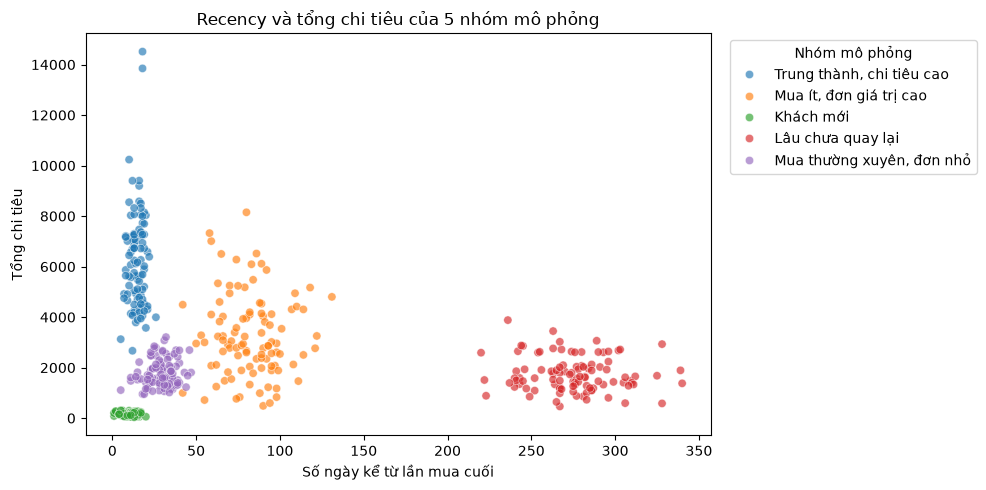

In [101]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=mau_co_id,
    x="recency_days",
    y="total_spent",
    hue="nhom",
    alpha=0.65
)

plt.title("Recency và tổng chi tiêu của 5 nhóm mô phỏng")
plt.xlabel("Số ngày kể từ lần mua cuối")
plt.ylabel("Tổng chi tiêu")
plt.legend(title="Nhóm mô phỏng", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

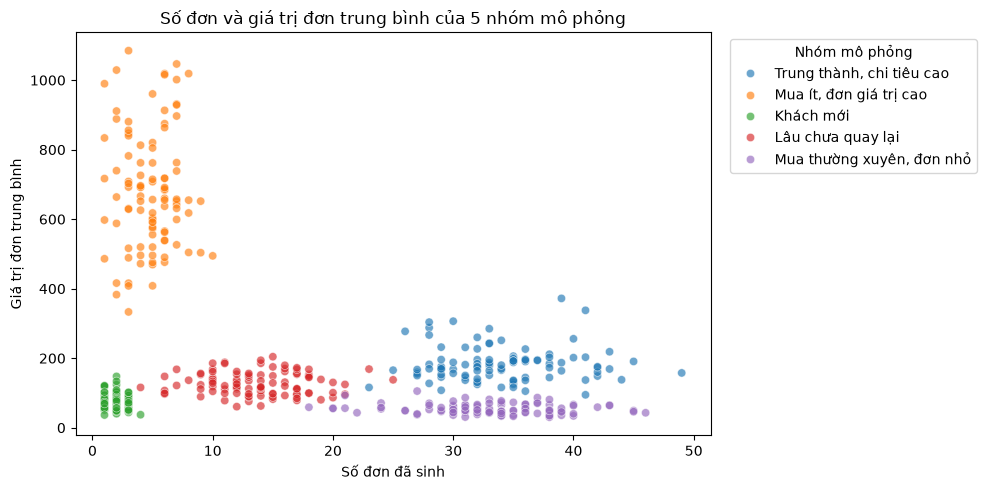

In [102]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=mau_co_id,
    x="so_don",
    y="avg_order_value",
    hue="nhom",
    alpha=0.65
)

plt.title("Số đơn và giá trị đơn trung bình của 5 nhóm mô phỏng")
plt.xlabel("Số đơn đã sinh")
plt.ylabel("Giá trị đơn trung bình")
plt.legend(title="Nhóm mô phỏng", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### 3.3. Xuất và kiểm tra bộ mô phỏng

In [103]:
import os

file_ho_so = "../Data/simulated/customers_simulated_5groups.csv"
file_bang_phu = "../Data/simulated/customers_simulated_5groups_metadata.csv"

khach_hang_mo_phong.to_csv(
    file_ho_so,
    index=False,
    date_format="%Y-%m-%d",
    encoding="utf-8-sig"
)

bang_phu_mo_phong.to_csv(
    file_bang_phu,
    index=False,
    encoding="utf-8-sig"
)

print("Đường dẫn file hồ sơ:", os.path.abspath(file_ho_so))
print("Đường dẫn file bảng phụ:", os.path.abspath(file_bang_phu))

Đường dẫn file hồ sơ: d:\T-sne_dataprocessing\Data\simulated\customers_simulated_5groups.csv
Đường dẫn file bảng phụ: d:\T-sne_dataprocessing\Data\simulated\customers_simulated_5groups_metadata.csv


In [104]:
ho_so_doc_lai = pd.read_csv(file_ho_so, dtype={"customer_id": "string"})
bang_phu_doc_lai = pd.read_csv(file_bang_phu, dtype={"customer_id": "string"})

print("Kích thước file hồ sơ:", ho_so_doc_lai.shape)
print("Kích thước file bảng phụ:", bang_phu_doc_lai.shape)

print("Cột hồ sơ khớp nguồn:",
      ho_so_doc_lai.columns.equals(df.columns))

print("ID hai file khớp theo từng dòng:",
      ho_so_doc_lai["customer_id"].equals(
          bang_phu_doc_lai["customer_id"]
      ))

Kích thước file hồ sơ: (500, 10)
Kích thước file bảng phụ: (500, 4)
Cột hồ sơ khớp nguồn: True
ID hai file khớp theo từng dòng: True


## 4. Làm sạch và tạo đặc trưng cho mô hình

In [105]:
khach_hang_sach = df.copy()

khach_hang_sach.insert(
    0,
    "record_id",
    range(1, len(khach_hang_sach) + 1)
)

display(khach_hang_sach[["record_id", "customer_id", "name"]].head())

,record_id,customer_id,name
0,1,CUST-45131,Jessica Jenkins
1,2,CUST-74728,Miranda Turner
2,3,CUST-57845,Kelly Smith
3,4,CUST-88800,Kenneth Smith
4,5,CUST-91943,Brian Miller


In [106]:
print("Kích thước bảng làm việc:", khach_hang_sach.shape)
print("Số dòng đã loại:", len(df) - len(khach_hang_sach))
print("Mã bản ghi duy nhất:", khach_hang_sach["record_id"].is_unique)
print("Mã khách hàng nguồn được giữ:",
      khach_hang_sach["customer_id"].equals(df["customer_id"]))

Kích thước bảng làm việc: (100000, 11)
Số dòng đã loại: 0
Mã bản ghi duy nhất: True
Mã khách hàng nguồn được giữ: True


In [107]:
cot_ngay = ["first_purchase_date", "last_purchase_date"]

for cot in cot_ngay:
    khach_hang_sach[cot] = pd.to_datetime(
        khach_hang_sach[cot],
        format="%Y-%m-%d",
        errors="raise"
    )

print(khach_hang_sach[cot_ngay].dtypes)

first_purchase_date    datetime64[us]
last_purchase_date     datetime64[us]
dtype: object


In [108]:
ngay_tham_chieu = pd.Timestamp("2025-05-05")

khach_hang_sach["recency_days"] = (
    ngay_tham_chieu - khach_hang_sach["last_purchase_date"]
).dt.days

display(khach_hang_sach[[
    "record_id", "last_purchase_date", "recency_days"
]].head())

print("Kích thước bảng:", khach_hang_sach.shape)
print("Số Recency bị thiếu:", khach_hang_sach["recency_days"].isna().sum())
print("Recency nhỏ nhất:", khach_hang_sach["recency_days"].min())
print("Recency lớn nhất:", khach_hang_sach["recency_days"].max())

,record_id,last_purchase_date,recency_days
0,1,2024-10-27,190
1,2,2024-07-20,289
2,3,2025-01-25,100
3,4,2024-05-10,360
4,5,2024-07-25,284


Kích thước bảng: (100000, 12)
Số Recency bị thiếu: 0
Recency nhỏ nhất: 1
Recency lớn nhất: 366


### 4.1. Chọn các cột đầu vào cho mô hình

In [109]:
cot_dac_trung = [
    "total_spent",
    "avg_order_value",
    "loyalty_points",
    "support_tickets",
    "subscription",
    "favorite_category",
    "recency_days"
]

dac_trung_chinh_thuc = (
    khach_hang_sach
    .set_index("record_id", verify_integrity=True)
    [cot_dac_trung]
    .copy()
)

display(dac_trung_chinh_thuc.head())

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_12836\1832899311.py:13: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  .set_index("record_id", verify_integrity=True)


,total_spent,avg_order_value,loyalty_points,support_tickets,subscription,favorite_category,recency_days
record_id,,,,,,,
1,3265.97,71.00,4822,1,False,Toys,190
2,8016.76,190.88,1998,8,False,Electronics,289
3,7828.50,186.39,1486,6,False,Books,100
4,4184.57,92.99,2697,3,True,Beauty,360
5,2559.50,134.71,3362,8,False,Home & Kitchen,284


In [110]:
print("Kích thước bảng:", dac_trung_chinh_thuc.shape)

print("Mã bản ghi khớp bảng sạch:",
      dac_trung_chinh_thuc.index.equals(
          pd.Index(khach_hang_sach["record_id"])
      ))

print("Số ô thiếu theo cột:")
print(dac_trung_chinh_thuc.isna().sum())

Kích thước bảng: (100000, 7)
Mã bản ghi khớp bảng sạch: True
Số ô thiếu theo cột:
total_spent          0
avg_order_value      0
loyalty_points       0
support_tickets      0
subscription         0
favorite_category    0
recency_days         0
dtype: int64


### 4.2. Giảm độ lệch của giá trị đơn hàng bằng log


In [111]:
aov_goc = dac_trung_chinh_thuc["avg_order_value"]
aov_log = np.log1p(aov_goc)

print("Skewness gốc:", round(aov_goc.skew(), 4))
print("Skewness sau log:", round(aov_log.skew(), 4))


Skewness gốc: 5.7214
Skewness sau log: -0.0593


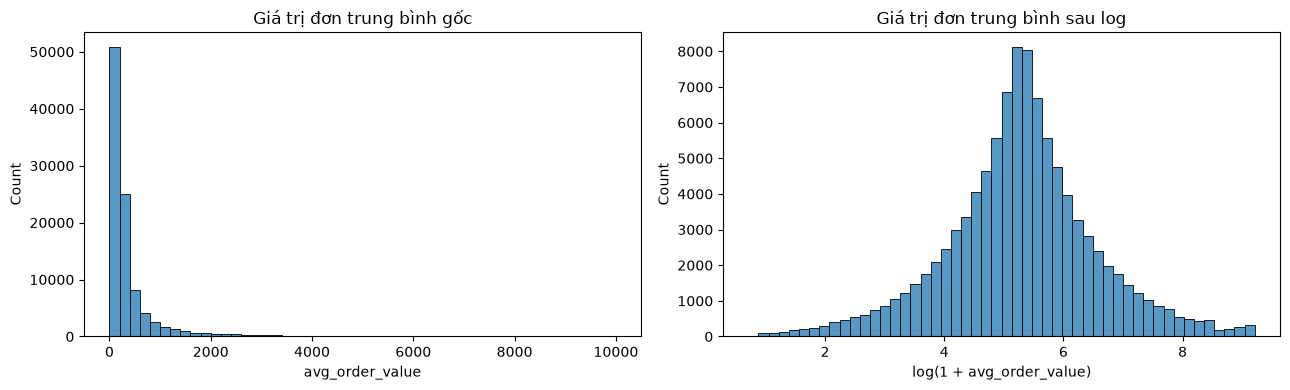

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(x=aov_goc, bins=50, ax=axes[0])
axes[0].set_title("Giá trị đơn trung bình gốc")
axes[0].set_xlabel("avg_order_value")

sns.histplot(x=aov_log, bins=50, ax=axes[1])
axes[1].set_title("Giá trị đơn trung bình sau log")
axes[1].set_xlabel("log(1 + avg_order_value)")

plt.tight_layout()
plt.show()

### Vì sao biến đổi `avg_order_value`?

Quy tắc IQR đánh dấu 11.408 hồ sơ để xem xét. Quy trình giữ các hồ sơ
này và dùng `log1p` để giảm độ lệch phải của `avg_order_value`.
Skewness giảm từ `5.7214` xuống `-0.0593`. Sau mã hóa danh mục,
bảng đầu vào có 13 đặc trưng, gồm 5 cột số được chuẩn hóa và 8 cột `0/1`.

In [113]:
print("Skewness sau log:", round(aov_log.skew(), 4))

Skewness sau log: -0.0593


In [114]:
dac_trung_bien_doi = dac_trung_chinh_thuc.copy()
dac_trung_bien_doi["avg_order_value_log"] = aov_log
dac_trung_bien_doi = dac_trung_bien_doi.drop(columns="avg_order_value")

print("Kích thước:", dac_trung_bien_doi.shape)
display(dac_trung_bien_doi.head())

Kích thước: (100000, 7)


,total_spent,loyalty_points,support_tickets,subscription,favorite_category,recency_days,avg_order_value_log
record_id,,,,,,,
1,3265.97,4822,1,False,Toys,190,4.276666
2,8016.76,1998,8,False,Electronics,289,5.256870
3,7828.50,1486,6,False,Books,100,5.233192
4,4184.57,2697,3,True,Beauty,360,4.543188
5,2559.50,3362,8,False,Home & Kitchen,284,4.910520


In [115]:
dac_trung_bien_doi = dac_trung_chinh_thuc.copy()
dac_trung_bien_doi["avg_order_value_log"] = aov_log
dac_trung_bien_doi = dac_trung_bien_doi.drop(columns="avg_order_value")

print("Kích thước:", dac_trung_bien_doi.shape)
display(dac_trung_bien_doi.head())

Kích thước: (100000, 7)


,total_spent,loyalty_points,support_tickets,subscription,favorite_category,recency_days,avg_order_value_log
record_id,,,,,,,
1,3265.97,4822,1,False,Toys,190,4.276666
2,8016.76,1998,8,False,Electronics,289,5.256870
3,7828.50,1486,6,False,Books,100,5.233192
4,4184.57,2697,3,True,Beauty,360,4.543188
5,2559.50,3362,8,False,Home & Kitchen,284,4.910520


### 4.3. Mã hóa trạng thái đăng ký và danh mục yêu thích

In [116]:
dac_trung_bien_doi["subscription"] = dac_trung_bien_doi["subscription"].astype(int)

display(dac_trung_bien_doi["subscription"].head())
display(dac_trung_bien_doi["subscription"].value_counts().sort_index())

record_id
1    0
2    0
3    0
4    1
5    0
Name: subscription, dtype: int64

subscription
0    50071
1    49929
Name: count, dtype: int64

In [117]:
dac_trung_ma_hoa = pd.get_dummies(
    dac_trung_bien_doi,
    columns=["favorite_category"],
    dtype=int,
)

cot_danh_muc = dac_trung_ma_hoa.filter(like="favorite_category_")

print("Kích thước bảng:", dac_trung_ma_hoa.shape)
print("Mỗi hồ sơ có đúng một danh mục:", (cot_danh_muc.sum(axis=1) == 1).all())
display(cot_danh_muc.head())

Kích thước bảng: (100000, 13)
Mỗi hồ sơ có đúng một danh mục: True


,favorite_category_Beauty,favorite_category_Books,favorite_category_Clothing,favorite_category_Electronics,favorite_category_Home & Kitchen,favorite_category_Sports,favorite_category_Toys
record_id,,,,,,,
1,0,0,0,0,0,0,1
2,0,0,0,1,0,0,0
3,0,1,0,0,0,0,0
4,1,0,0,0,0,0,0
5,0,0,0,0,1,0,0


### 4.4. Chuẩn hóa 5 đặc trưng số

In [118]:
from sklearn.preprocessing import StandardScaler

cot_can_chuan_hoa = [
    "total_spent",
    "avg_order_value_log",
    "loyalty_points",
    "support_tickets",
    "recency_days",
]

scaler = StandardScaler()
dac_trung_chuan_hoa = dac_trung_ma_hoa.copy()

dac_trung_chuan_hoa[cot_can_chuan_hoa] = scaler.fit_transform(
    dac_trung_ma_hoa[cot_can_chuan_hoa]
)

In [119]:
bang_kiem_tra = dac_trung_chuan_hoa[cot_can_chuan_hoa]

display(pd.DataFrame({
    "trung_binh": bang_kiem_tra.mean(),
    "do_lech_chuan": bang_kiem_tra.std(ddof=0),
}).round(6))

print("Kích thước bảng:", dac_trung_chuan_hoa.shape)

,trung_binh,do_lech_chuan
total_spent,0.0,1.0
avg_order_value_log,0.0,1.0
loyalty_points,-0.0,1.0
support_tickets,0.0,1.0
recency_days,-0.0,1.0


Kích thước bảng: (100000, 13)


In [120]:
display(df["favorite_category"].value_counts())

favorite_category
Home & Kitchen    14474
Clothing          14421
Books             14352
Sports            14272
Electronics       14206
Toys              14154
Beauty            14121
Name: count, dtype: int64

## 5. Đối chiếu module và xuất dữ liệu bàn giao

In [132]:
import os
import sys

import pandas as pd

thu_muc_du_an = "." if os.path.isfile("preprocess_customers.py") else ".."
sys.path.insert(0, os.path.abspath(thu_muc_du_an))

from preprocess_customers import tien_xu_ly_huan_luyen

sach_module, chuan_hoa_module, scaler_module, danh_muc_module = (
    tien_xu_ly_huan_luyen(df)
)

pd.testing.assert_frame_equal(sach_module, khach_hang_sach)
pd.testing.assert_frame_equal(chuan_hoa_module, dac_trung_chuan_hoa)

print("Cả hai bảng từ module đều khớp với notebook.")

Cả hai bảng từ module đều khớp với notebook.


### 5.1. Xuất 3 file customers_clean.csv, customers_scaled.csv và scaler.pkl.

In [133]:
import os

import joblib

thu_muc_xuat = os.path.join(
    os.path.abspath(thu_muc_du_an), "Data", "processed"
)
os.makedirs(thu_muc_xuat, exist_ok=True)

sach_module.to_csv(
    os.path.join(thu_muc_xuat, "customers_clean.csv"),
    index=False,
    date_format="%Y-%m-%d",
)

chuan_hoa_module.to_csv(
    os.path.join(thu_muc_xuat, "customers_scaled.csv"),
    index=True,
    index_label="record_id",
)

joblib.dump(
    {
        "scaler": scaler_module,
        "danh_muc_chuan": danh_muc_module,
    },
    os.path.join(thu_muc_xuat, "scaler.pkl"),
)

print("Đã xuất 3 file vào:", thu_muc_xuat)

Đã xuất 3 file vào: d:\T-sne_dataprocessing\Data\processed


In [134]:
import os

import joblib

bo_tien_xu_ly = joblib.load(os.path.join(thu_muc_xuat, "scaler.pkl"))
scaler_da_luu = bo_tien_xu_ly["scaler"]

print("Loại scaler:", type(scaler_da_luu).__name__)
print("Số cột số đã fit:", scaler_da_luu.n_features_in_)
print("Danh mục chuẩn:", bo_tien_xu_ly["danh_muc_chuan"])

Loại scaler: StandardScaler
Số cột số đã fit: 5
Danh mục chuẩn: ['Beauty', 'Books', 'Clothing', 'Electronics', 'Home & Kitchen', 'Sports', 'Toys']


In [135]:
import os

import pandas as pd

bang_sach_doc_lai = pd.read_csv(
    os.path.join(thu_muc_xuat, "customers_clean.csv")
)
bang_scaled_doc_lai = pd.read_csv(
    os.path.join(thu_muc_xuat, "customers_scaled.csv")
)

ma_sach = bang_sach_doc_lai["record_id"]
ma_scaled = bang_scaled_doc_lai["record_id"]

print("Kích thước file clean:", bang_sach_doc_lai.shape)
print("Kích thước file scaled:", bang_scaled_doc_lai.shape)
print("Mã hồ sơ duy nhất trong cả hai file:", ma_sach.is_unique and ma_scaled.is_unique)
print("Mã hồ sơ khớp theo từng dòng:", ma_sach.equals(ma_scaled))

Kích thước file clean: (100000, 12)
Kích thước file scaled: (100000, 14)
Mã hồ sơ duy nhất trong cả hai file: True
Mã hồ sơ khớp theo từng dòng: True
